# AI-Powered Research Paper Finder and Summarizer

Semantic search (Sentence-BERT + FAISS) compared with a TF-IDF baseline over arXiv AI/ML papers, plus abstract summarization evaluated with ROUGE on SciTLDR.

**Based on:** [Arxiv-Neural-Search](https://github.com/karndeb/Arxiv-Neural-Search) by karndeb (GPL-3.0). **New in this project:** TF-IDF baseline, comparison of embedding models, retrieval evaluation (Recall@k, MRR), summarization with ROUGE and manual checks, and a new Streamlit app.

**How to run:** run the cells from top to bottom in Google Colab. Processed files are cached in the Google Drive folder `Arxiv`, so slow steps are skipped when the files already exist.

Note: summaries and search results need human verification.

In [1]:
!pip install -q sentence-transformers faiss-cpu scikit-learn transformers evaluate rouge_score matplotlib pandas numpy tqdm streamlit

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import os, json, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import faiss, torch
from google.colab import drive

drive.mount('/content/gdrive')
FOLDER = '/content/gdrive/MyDrive/Arxiv/'
os.makedirs(FOLDER, exist_ok=True)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)

Mounted at /content/gdrive
device: cpu


## Part 1. Data: arXiv papers

Source: arXiv metadata snapshot (`gs://arxiv-dataset/metadata-v5/arxiv-metadata-oai.json`, also on Kaggle). Only the categories cs.CL, cs.IR, cs.LG, cs.HC and cs.CV are kept, and duplicate abstracts are removed.

The results in the report were produced with the saved file `papers_clean.csv` (about 25.6 thousand unique papers, up to April 2020). The optional cell below shows how a similar paper table is built from the snapshot. A rebuilt file can differ slightly from the one used for the reported numbers.

In [3]:
REBUILD = False   # True = rebuild the paper table from the 4.5 GB snapshot file stored in Drive
N_PAPERS = 25649  # size of the table used in the report

if REBUILD:
    import tqdm
    src = '/content/gdrive/MyDrive/arxiv-metadata-oai.json'
    keep = {'cs.CL', 'cs.IR', 'cs.LG', 'cs.HC', 'cs.CV'}
    new_id = re.compile(r'^\d{4}\.\d{4,5}$')
    rows = []
    with tqdm.tqdm(total=os.path.getsize(src)) as pbar:
        with open(src, 'r') as f:
            for line in f:
                pbar.update(len(line))
                if not any(c in line for c in keep):
                    continue
                p = json.loads(line)
                cats = p.get('categories', [])
                if isinstance(cats, str):
                    cats = cats.split()
                if not new_id.match(str(p.get('id'))) or not (set(cats) & keep):
                    continue
                rows.append({'arxiv_id': p['id'],
                             'clean_title': ' '.join(str(p.get('title')).split()),
                             'clean_abstracts': ' '.join(str(p.get('abstract')).split()),
                             'categories': ' '.join(cats),
                             'authors': str(p.get('authors'))})
    papers = pd.DataFrame(rows).drop_duplicates('clean_abstracts')
    papers = papers.sort_values('arxiv_id', ascending=False).head(N_PAPERS).reset_index(drop=True)
    papers['url'] = 'https://arxiv.org/abs/' + papers['arxiv_id']
    papers.to_csv(FOLDER + 'papers_clean.csv', index=False)
    print('rebuilt:', len(papers))

In [4]:
df = pd.read_csv(FOLDER + 'papers_clean.csv')
df['clean_title'] = df['clean_title'].fillna('').astype(str)
df['clean_abstracts'] = df['clean_abstracts'].fillna('').astype(str)
print(len(df), 'papers;', 'columns:', list(df.columns))

# small sample of the processed table for the GitHub repository
cols = ['arxiv_id', 'clean_title', 'clean_abstracts', 'authors', 'categories', 'url']
df[cols].head(1000).to_csv(FOLDER + 'papers_sample_1000.csv', index=False)

df[['arxiv_id', 'clean_title', 'url']].head()

25649 papers; columns: ['id', 'arxiv_id', 'title', 'abstract', 'categories', 'authors', 'clean_title', 'clean_abstracts', 'url']


,arxiv_id,clean_title,url
0,2004.08361,Unsupervised Discovery of Implicit Gender Bias,https://arxiv.org/abs/2004.08361
1,2004.08346,An integrated light management system with rea...,https://arxiv.org/abs/2004.08346
2,2004.08270,Weakly Supervised Geodesic Segmentation of Egy...,https://arxiv.org/abs/2004.08270
3,2004.08222,Learning to Predict Context-adaptive Convoluti...,https://arxiv.org/abs/2004.08222
4,2004.08206,Vehicle Position Estimation with Aerial Imager...,https://arxiv.org/abs/2004.08206


## Part 2. Paper retrieval: TF-IDF baseline vs semantic search

In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sentence_transformers import SentenceTransformer

# TF-IDF baseline
tfidf = TfidfVectorizer(stop_words='english', max_features=200000)
D = tfidf.fit_transform(df['clean_abstracts'])

# Semantic search model: all-MiniLM-L6-v2 (embeddings are cached in Drive)
minilm = SentenceTransformer('all-MiniLM-L6-v2', device=device)
emb_path = FOLDER + 'embeddings_minilm.npy'
if os.path.exists(emb_path) and len(np.load(emb_path, mmap_mode='r')) == len(df):
    emb = np.load(emb_path).astype('float32')
else:
    emb = minilm.encode(df['clean_abstracts'].tolist(), batch_size=128, show_progress_bar=True,
                        normalize_embeddings=True).astype('float32')
    np.save(emb_path, emb)

index = faiss.IndexFlatIP(emb.shape[1])
index.add(emb)
print('embeddings:', emb.shape)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:01<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

embeddings: (25649, 384)


In [6]:
def semantic_search(query, k=5):
    q = minilm.encode([query], normalize_embeddings=True).astype('float32')
    scores, ids = index.search(q, k)
    for s, i in zip(scores[0], ids[0]):
        print(round(float(s), 3), '|', df.iloc[int(i)]['clean_title'], '|', df.iloc[int(i)]['url'])

semantic_search('how to summarize scientific papers')
print()
semantic_search('making neural networks hard to fool')

0.794 | A Study of Human Summaries of Scientific Articles | https://arxiv.org/abs/2002.03604
0.669 | A Summarization System for Scientific Documents | https://arxiv.org/abs/1908.11152
0.647 | TalkSumm: A Dataset and Scalable Annotation Method for Scientific Paper Summarization Based on Conference Talks | https://arxiv.org/abs/1906.01351
0.636 | Structured Summarization of Academic Publications | https://arxiv.org/abs/1905.07695
0.636 | GASP! Generating Abstracts of Scientific Papers from Abstracts of Cited Papers | https://arxiv.org/abs/2003.04996

0.622 | Towards Robust Deep Neural Networks with BANG | https://arxiv.org/abs/1612.00138
0.617 | Certified Defenses against Adversarial Examples | https://arxiv.org/abs/1801.09344
0.615 | Learning Adversary-Resistant Deep Neural Networks | https://arxiv.org/abs/1612.01401
0.61 | A Formalization of Robustness for Deep Neural Networks | https://arxiv.org/abs/1903.10033
0.602 | Adversarial Example Defenses: Ensembles of Weak Defenses are not St

### Retrieval evaluation

500 random papers are used. The query is the paper title, and the correct result is the abstract of the same paper. Metrics: Recall@k (is the correct paper in the top k?) and MRR (mean reciprocal rank). The three methods are TF-IDF, the DistilBERT model of the original project, and MiniLM.

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.82k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/555 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  265MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

                       Recall@1  Recall@5  Recall@10    MRR
TF-IDF                    0.554     0.754      0.806  0.642
MiniLM                    0.704     0.876      0.934  0.784
DistilBERT (original)     0.184     0.314      0.376  0.247


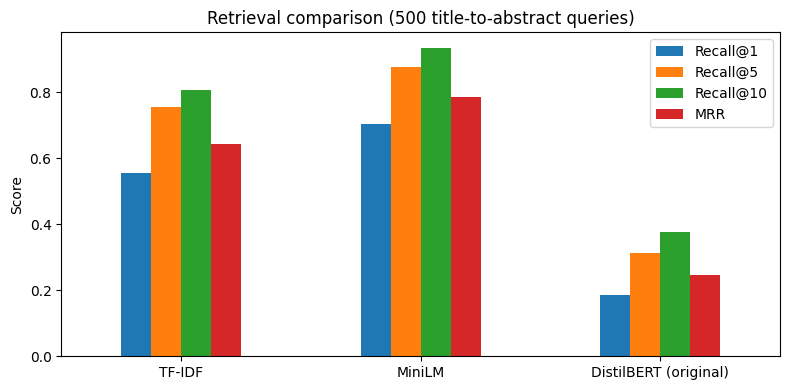

In [7]:
rng = np.random.default_rng(42)
q_idx = rng.choice(len(df), size=500, replace=False)
queries = df['clean_title'].iloc[q_idx].tolist()


def evaluate_retrieval(sim, correct, ks=(1, 5, 10)):
    ranks = np.array([int((row > row[c]).sum()) + 1 for row, c in zip(sim, correct)])
    out = {}
    for k in ks:
        out['Recall@' + str(k)] = round(float((ranks <= k).mean()), 3)
    out['MRR'] = round(float((1 / ranks).mean()), 3)
    return out


results = {}
results['TF-IDF'] = evaluate_retrieval(cosine_similarity(tfidf.transform(queries), D), q_idx)

Q = minilm.encode(queries, batch_size=64, normalize_embeddings=True)
results['MiniLM'] = evaluate_retrieval(Q @ emb.T, q_idx)

# Model of the original project (uses its cached embeddings if they exist)
old_path = FOLDER + 'embeddings.npy'
if os.path.exists(old_path) and len(np.load(old_path, mmap_mode='r')) == len(df):
    old_model = SentenceTransformer('sentence-transformers/distilbert-base-nli-stsb-mean-tokens', device=device)
    old_emb = np.load(old_path).astype('float32')
    Qo = old_model.encode(queries, batch_size=64).astype('float32')
    faiss.normalize_L2(Qo)
    results['DistilBERT (original)'] = evaluate_retrieval(Qo @ old_emb.T, q_idx)

res_df = pd.DataFrame(results).T
print(res_df)
res_df.to_csv(FOLDER + 'retrieval_results.csv')

ax = res_df.plot(kind='bar', figsize=(8, 4))
ax.set_ylabel('Score')
ax.set_title('Retrieval comparison (500 title-to-abstract queries)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(FOLDER + 'retrieval_comparison_final.png', dpi=200)
plt.show()

## Part 3. Summarization and ROUGE

Model: `sshleifer/distilbart-cnn-12-6`. Dataset: SciTLDR (SciTLDR-A test set, abstracts with author-written TLDRs). ROUGE is computed on the first 100 test papers against the first reference TLDR of each paper.

In [8]:
!git clone -q https://github.com/allenai/SciTLDR.git
rows = [json.loads(line) for line in open('SciTLDR/SciTLDR-Data/SciTLDR-A/test.jsonl')]
sci_docs = [' '.join(r['source']) for r in rows]
sci_refs = [r['target'][0] for r in rows]
print(len(rows), 'test papers. Example title:', rows[0]['title'])

618 test papers. Example title: FearNet: Brain-Inspired Model for Incremental Learning


In [10]:
import evaluate
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

name = 'sshleifer/distilbart-cnn-12-6'
tok = AutoTokenizer.from_pretrained(name)
sm = AutoModelForSeq2SeqLM.from_pretrained(name).to(device)


def summarize(texts, max_len=60, min_len=10, batch=8):
    outs = []
    for i in range(0, len(texts), batch):
        enc = tok(texts[i:i + batch], return_tensors='pt', truncation=True,
                  max_length=1024, padding=True).to(sm.device)
        with torch.no_grad():
            ids = sm.generate(**enc, max_length=max_len, min_length=min_len, num_beams=4)
        outs += tok.batch_decode(ids, skip_special_tokens=True)
    return outs


N_EVAL = 100   # on CPU this takes several minutes
preds = summarize(sci_docs[:N_EVAL])
rouge = evaluate.load('rouge')
scores = rouge.compute(predictions=preds, references=sci_refs[:N_EVAL])
print({k: round(float(v), 3) for k, v in scores.items()})

pd.DataFrame({'abstract': sci_docs[:N_EVAL], 'model_summary': preds, 'human_tldr': sci_refs[:N_EVAL]}) \
  .to_csv(FOLDER + 'summaries_100.csv', index=False)

Loading weights:   0%|          | 0/358 [00:00<?, ?it/s]

{'rouge1': 0.267, 'rouge2': 0.098, 'rougeL': 0.195, 'rougeLsum': 0.195}


### Manual check (relevance and factual consistency)

Ten generated summaries are read next to their abstracts. Each is scored from 1 to 5 for relevance (does it capture the main idea?) and factual consistency (is everything supported by the abstract?).

In [11]:
for i in range(3, 13):
    print(i, '| ABSTRACT:', sci_docs[i][:600])
    print('    SUMMARY :', preds[i].strip())
    print()

3 | ABSTRACT: Most recent gains in visual recognition have originated from the inclusion of attention mechanisms in deep convolutional networks (DCNs). Because these networks are optimized for object recognition, they learn where to attend using only a weak form of supervision derived from image class labels. Here, we demonstrate the benefit of using stronger supervisory signals by teaching DCNs to attend to image regions that humans deem important for object recognition. We first describe a large-scale online experiment (ClickMe) used to supplement ImageNet with nearly half a million human-derived "top-dow
    SUMMARY : Recent gains in visual recognition have originated from the inclusion of attention mechanisms in deep convolutional networks . Here, we demonstrate the benefit of using stronger supervisory signals by teaching DCNs to attend to image regions that humans deem important for object recognition .

4 | ABSTRACT: In recent years, deep neural networks have demonstrated outsta

**Manual check scores** (fill in with your own scores, then add the averages):

| Paper | Relevance (1-5) | Factual consistency (1-5) | Notes |
|---|---|---|---|
| 3 |  |  |  |
| 4 |  |  |  |
| 5 |  |  |  |
| 6 |  |  |  |
| 7 |  |  |  |
| 8 |  |  |  |
| 9 |  |  |  |
| 10 |  |  |  |
| 11 |  |  |  |
| 12 |  |  |  |
| **Average** |  |  |  |

## Part 4. Streamlit app

The app (`app.py` in this repository) searches with semantic search or TF-IDF, shows the abstract and the arXiv link, and creates a summary on request. Copy `app.py` to the Drive folder `Arxiv` and run the cell below in Colab. It prints a link that works while the cell session is running.

In [12]:
import subprocess, time, re

APP = FOLDER + 'app.py'   # copy of app.py from this repository

if not subprocess.run(['pgrep', '-f', 'streamlit run'], capture_output=True, text=True).stdout.strip():
    st_log = open('/content/st.log', 'w')
    subprocess.Popen(['streamlit', 'run', APP, '--server.port', '8501', '--server.headless', 'true'],
                     stdout=st_log, stderr=st_log)
    time.sleep(10)

!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O /content/cloudflared
!chmod +x /content/cloudflared

cf_log = open('/content/cf.log', 'w')
subprocess.Popen(['/content/cloudflared', 'tunnel', '--url', 'http://localhost:8501'], stdout=cf_log, stderr=cf_log)

url = None
for _ in range(30):
    time.sleep(2)
    m = re.search(r'https://[a-z0-9-]+\.trycloudflare\.com', open('/content/cf.log').read())
    if m:
        url = m.group(0)
        break
print('OPEN THIS LINK:', url if url else 'no link yet - run: !tail -20 /content/cf.log')

OPEN THIS LINK: https://gods-novels-cached-epic.trycloudflare.com


## Limitations

- The paper collection ends around April 2020.
- The retrieval test uses titles as queries, which share many words with their own abstracts. This helps TF-IDF.
- The summarizer was trained on news articles. It often copies sentences from the abstract and can end mid-sentence.
- ROUGE is low because SciTLDR references are one sentence and the model writes longer text.
- Summaries need human verification.